<a href="https://colab.research.google.com/github/elliottcollardd-ui/Fraud-explorer/blob/main/DataSorting(NASA).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

cols = ["unit", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]
df = pd.read_csv("train_FD001.txt", sep=r"\s+",header=None, names=cols)
df.head()

,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [13]:
print(df.shape)
print(df.isna().sum())
df.describe()

(20631, 26)
unit     0
cycle    0
op1      0
op2      0
op3      0
s1       0
s2       0
s3       0
s4       0
s5       0
s6       0
s7       0
s8       0
s9       0
s10      0
s11      0
s12      0
s13      0
s14      0
s15      0
s16      0
s17      0
s18      0
s19      0
s20      0
s21      0
dtype: int64


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,2.063100e+04,20631.000000,20631.000000,20631.000000,2.063100e+04,...,20631.000000,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,100.0,5.186700e+02,642.680934,1590.523119,1408.933782,1.462000e+01,...,521.413470,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705
std,29.227633,68.880990,0.002187,0.000293,0.0,6.537152e-11,0.500053,6.131150,9.000605,3.394700e-12,...,0.737553,0.071919,19.076176,0.037505,1.556432e-14,1.548763,0.0,0.0,0.180746,0.108251
min,1.000000,1.000000,-0.008700,-0.000600,100.0,5.186700e+02,641.210000,1571.040000,1382.250000,1.462000e+01,...,518.690000,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200
25%,26.000000,52.000000,-0.001500,-0.000200,100.0,5.186700e+02,642.325000,1586.260000,1402.360000,1.462000e+01,...,520.960000,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800
50%,52.000000,104.000000,0.000000,0.000000,100.0,5.186700e+02,642.640000,1590.100000,1408.040000,1.462000e+01,...,521.480000,2388.090000,8140.540000,8.438900,3.000000e-02,393.000000,2388.0,100.0,38.830000,23.297900
75%,77.000000,156.000000,0.001500,0.000300,100.0,5.186700e+02,643.000000,1594.380000,1414.555000,1.462000e+01,...,521.950000,2388.140000,8148.310000,8.465600,3.000000e-02,394.000000,2388.0,100.0,38.950000,23.366800
max,100.000000,362.000000,0.008700,0.000600,100.0,5.186700e+02,644.530000,1616.910000,1441.490000,1.462000e+01,...,523.380000,2388.560000,8293.720000,8.584800,3.000000e-02,400.000000,2388.0,100.0,39.430000,23.618400


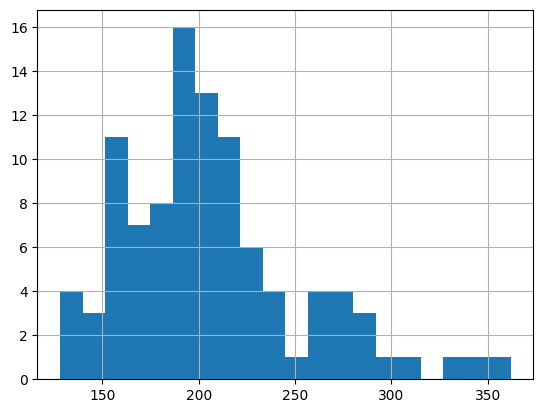

In [14]:
life = df.groupby("unit")["cycle"].max()
life.hist(bins=20)
plt.show()

In [15]:
flat = [c for c in df.columns if df[c].nunique() == 1]
print(flat)
df = df.drop(columns=flat)

['op3', 's1', 's5', 's10', 's16', 's18', 's19']


<function matplotlib.pyplot.show(close=None, block=None)>

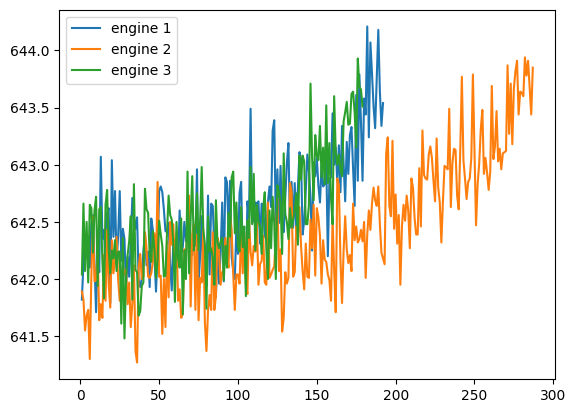

In [16]:
for u in [1, 2, 3]:
  d = df[df.unit == u]
  plt.plot(d.cycle, d.s2, label=f"engine {u}")
plt.legend()
plt.show()

In [17]:
df["rul"] = df.groupby("unit")["cycle"].transform("max") - df["cycle"]
df.corr()["rul"].sort_values()

,rul
cycle,-0.736241
s11,-0.696228
s4,-0.678948
s15,-0.642667
s2,-0.606484
s17,-0.606154
s3,-0.584520
s8,-0.563968
s13,-0.562569
s9,-0.390102


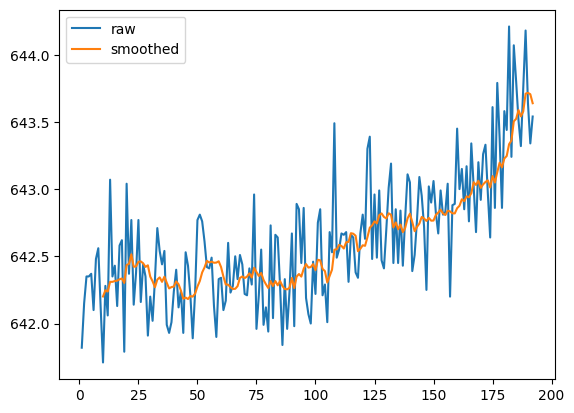

In [18]:
df["s2_smooth"] = df.groupby("unit")["s2"].transform(lambda x: x.rolling(10).mean())
d = df[df.unit == 1]
plt.plot(d.cycle, d.s2, label="raw")
plt.plot(d.cycle, d.s2_smooth, label="smoothed")
plt.legend()
plt.show()


In [19]:
print(life.min(), life.max(), life.mean())

128 362 206.31


In [20]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

features = [c for c in df.columns if c.startswith("s") and c != "s2_smooth"]
target = df["rul"].clip(upper=125)

model = RandomForestRegressor(n_estimators=100, random_state=0)
model.fit(df[features], target)

RandomForestRegressor(random_state=0)

In [21]:
test = pd.read_csv("test_FD001.txt", sep=r"\s+", header=None, names=cols)
truth = pd.read_csv("RUL_FD001.txt", header=None, names=["rul"])

last = test.groupby("unit").last()
pred = model.predict(last[features])

print(mean_squared_error(truth["rul"], pred) ** 0.5)
print(mean_squared_error(truth["rul"], [target.mean()] * 100) ** 0.5)

18.260596594854178
43.06703554245684
